# Sesi 2 — 01. Menyiapkan Data Trafik Milan *(pengajar)*

**Workshop Deep Learning untuk Mahasiswa Teknik Telekomunikasi — ITERA**

Notebook ini **hanya untuk pengajar**. Peserta cukup memakai hasilnya, `data/milano_duomo_5060.csv`, yang sudah ada di repo.

**Sumber data**

- *Telecom Italia Big Data Challenge 2014*: aktivitas seluler kota Milan, 1 Nov – 31 Des 2013, grid 100 × 100 kotak (± 235 m × 235 m), interval 10 menit. Barlacchi dkk. (2015), *Scientific Data* 2:150055. Lisensi ODbL. Data asli ± 21 GB.
- Versi agregat per jam `milano.h5` (308 MB) dari Zhang dkk. (2021), *Dual Attention-Based Federated Learning for Wireless Traffic Prediction*, IEEE INFOCOM — repo <https://github.com/chuanting/FedDA>.

**Cara mendapatkan `milano.h5`:** unduh dari tautan *Milano* di README repo FedDA (Google Drive), lalu simpan ke `sesi-2-rnn/data/milano.h5`. File ini tidak di-commit (`.gitignore`).

| Bagian | Isi |
|---|---|
| 1 | Membuka `milano.h5` |
| 2 | Peta rata-rata trafik internet kota Milan |
| 3 | Memilih kotak Duomo (pusat kota) |
| 4 | Menyimpan CSV kecil untuk peserta |

In [1]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Palet warna ITERA (sama dengan slide)
NAVY, GOLD, RED, TEAL, GREEN, GRAY = "#0B1F3A", "#D4A017", "#C8102E", "#1E8C8C", "#2E9E6B", "#5A5A5A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

DATA_DIR = Path("data")
HASIL_DIR = Path("hasil")
HASIL_DIR.mkdir(exist_ok=True)
H5_PATH = DATA_DIR / "milano.h5"
assert H5_PATH.exists(), "Unduh milano.h5 dulu (lihat petunjuk di atas)"

---
## 1. Membuka `milano.h5`

File HDF5 berisi beberapa *dataset* (mirip tabel NumPy):

- `net`, `call`, `sms` — matriks **jam × kotak** (1344 × 10000): aktivitas internet, telepon, dan SMS
- `idx` — *timestamp* tiap jam (detik sejak 1970)
- `cell`, `lat`, `lng` — ID kotak beserta koordinat pusatnya

In [2]:
f = h5py.File(H5_PATH, "r")
for key in f:
    print(f"{key:5s} {str(f[key].shape):14s} {f[key].dtype}")

call  (1344, 10000)  float64
cell  (9953,)        int64
idx   (1344, 1)      int64
lat   (9953,)        float64
lng   (9953,)        float64
net   (1344, 10000)  float64
sms   (1344, 10000)  float64


In [3]:
waktu = pd.to_datetime(f["idx"][()].ravel(), unit="s")
net, call, sms = f["net"][()], f["call"][()], f["sms"][()]
cell, lat, lng = f["cell"][()], f["lat"][()], f["lng"][()]

print("Periode :", waktu.min(), "->", waktu.max())
print("Jumlah  :", len(waktu), "jam =", len(waktu) // 24, "hari =", len(waktu) // 168, "minggu")
print("Langkah :", pd.Series(waktu).diff().dropna().unique())
print("NaN     :", np.isnan(net).sum(), np.isnan(call).sum(), np.isnan(sms).sum())

Periode : 2013-11-04 00:00:00 -> 2013-12-29 23:00:00
Jumlah  : 1344 jam = 56 hari = 8 minggu
Langkah : <TimedeltaArray>
['0 days 01:00:00']
Length: 1, dtype: timedelta64[s]
NaN     : 0 0 0


Catatan:

- Nilai **bukan** byte atau jumlah panggilan, melainkan **"aktivitas"** yang dinormalisasi Telecom Italia dengan konstanta yang dirahasiakan. Cocok untuk melihat pola, tetapi jangan dibaca sebagai Mbps.
- Periode dipotong menjadi **8 minggu penuh**, Senin 4 Nov – Minggu 29 Des 2013 (Natal termasuk, Tahun Baru tidak).

---
## 2. Peta Trafik Internet Kota Milan

ID kotak 1…10000 tersusun baris demi baris pada grid 100 × 100, sehingga rata-rata trafik tiap kotak dapat digambar sebagai peta.

Kotak terdekat dengan Duomo: 5060 (± 99 m dari katedral)


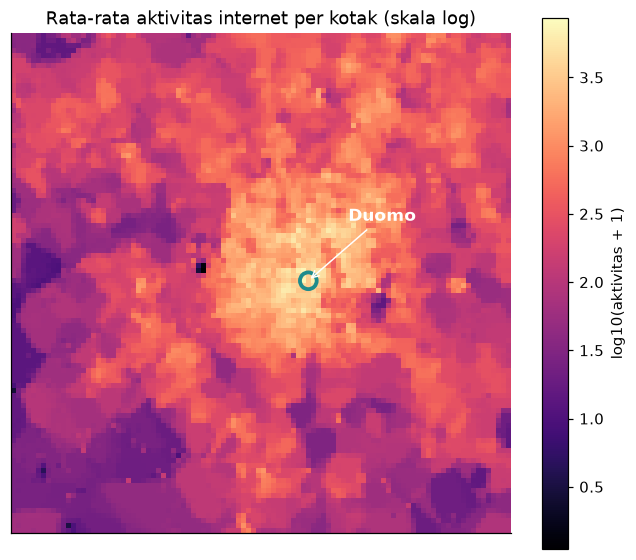

Kotak 5060 adalah kotak ke-95 tersibuk dari 10000


In [4]:
DUOMO = (45.4642, 9.1900)   # koordinat Katedral Duomo di Milano

jarak = np.hypot(lat - DUOMO[0], (lng - DUOMO[1]) * np.cos(np.radians(DUOMO[0])))
SQUARE_ID = int(cell[np.argmin(jarak)])
print(f"Kotak terdekat dengan Duomo: {SQUARE_ID} (± {jarak.min() * 111_000:.0f} m dari katedral)")

rata2 = net.mean(axis=0)                     # rata-rata per kotak, urut ID 1..10000
grid = rata2.reshape(100, 100)               # baris = (ID-1)//100, kolom = (ID-1)%100
baris, kolom = divmod(SQUARE_ID - 1, 100)

fig, ax = plt.subplots(figsize=(6, 5.2))
im = ax.imshow(np.log10(grid + 1), origin="lower", cmap="magma")
ax.scatter(kolom, baris, s=120, facecolors="none", edgecolors=TEAL, linewidths=2.5)
ax.annotate("Duomo", (kolom, baris), xytext=(kolom + 8, baris + 12), color="white", fontsize=11, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="white"))
ax.set_title("Rata-rata aktivitas internet per kotak (skala log)")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(im, ax=ax, label="log10(aktivitas + 1)")
plt.tight_layout()
plt.savefig(HASIL_DIR / "peta_milano.png", dpi=200, bbox_inches="tight")
plt.show()

peringkat = int((rata2 > rata2[SQUARE_ID - 1]).sum()) + 1
print(f"Kotak {SQUARE_ID} adalah kotak ke-{peringkat} tersibuk dari 10000")

---
## 3. Data Kotak Duomo

Kita ambil **satu kotak**: pusat kota di sekitar Duomo. Trafiknya tinggi dan pola hariannya jelas, cocok untuk belajar *forecasting*.

In [5]:
i = SQUARE_ID - 1
df = pd.DataFrame({"waktu": waktu, "net": net[:, i], "call": call[:, i], "sms": sms[:, i]})
print(df.describe().round(1))
df.head()

                     waktu     net    call     sms
count                 1344  1344.0  1344.0  1344.0
mean   2013-12-01 23:30:00  3331.9   473.8   512.5
min    2013-11-04 00:00:00   587.1     0.0     1.2
25%    2013-11-17 23:45:00  1188.9    28.9    80.8
50%    2013-12-01 23:30:00  2720.8   243.1   322.8
75%    2013-12-15 23:15:00  5280.5   912.6   926.8
max    2013-12-29 23:00:00  9261.6  1894.7  2137.4
std                    NaN  2238.5   496.0   478.6


,waktu,net,call,sms
0,2013-11-04 00:00:00,847.950,14.265,32.569
1,2013-11-04 01:00:00,790.814,17.301,20.802
2,2013-11-04 02:00:00,737.321,3.039,12.912
3,2013-11-04 03:00:00,733.932,3.531,1.812
4,2013-11-04 04:00:00,785.195,2.337,3.188


---
## 4. Simpan CSV untuk Peserta

Hanya 1344 baris × 4 kolom (± 50 KB), sehingga cukup di-commit ke repo. Peserta tidak perlu mengunduh `milano.h5`.

In [6]:
csv_path = DATA_DIR / f"milano_duomo_{SQUARE_ID}.csv"
df.to_csv(csv_path, index=False, float_format="%.3f")
print(f"Tersimpan: {csv_path} ({csv_path.stat().st_size / 1024:.0f} KB, {len(df)} baris)")

Tersimpan: data/milano_duomo_5060.csv (58 KB, 1344 baris)


---
## 5. Data untuk Tugas: 10 Lokasi Kelompok

Setiap kelompok tugas mendapat satu lokasi tambahan untuk **uji generalisasi** (Bagian D tugas): apakah konfigurasi terbaik di Duomo tetap bagus di tempat lain? Lokasi ditentukan oleh **digit terakhir NIM terkecil** di kelompok.

Lokasinya sengaja beragam: stasiun, kampus, kawasan malam, taman, stadion, dan bandara. Masing-masing punya pola harian dan minggu Natal yang berbeda.

In [7]:
LOKASI_TUGAS = {   # kode: (nama, lintang, bujur) titik acuan; dipakai kotak 235 m terdekat
    0: ("Stazione Centrale", 45.4861, 9.2045),
    1: ("Navigli (Darsena)", 45.4520, 9.1757),
    2: ("Universita Bocconi", 45.4507, 9.1890),
    3: ("Stadio San Siro", 45.4781, 9.1240),
    4: ("Politecnico di Milano", 45.4781, 9.2272),
    5: ("Bandara Linate", 45.4497, 9.2783),
    6: ("Parco Sempione", 45.4725, 9.1765),
    7: ("Universita Bicocca", 45.5137, 9.2108),
    8: ("CityLife", 45.4780, 9.1560),
    9: ("Corso Como", 45.4813, 9.1874),
}

tabel, potongan = [], []
for kode, (nama, la, lo) in LOKASI_TUGAS.items():
    d = np.hypot(lat - la, (lng - lo) * np.cos(np.radians(la)))
    kotak = int(cell[np.argmin(d)])
    j = kotak - 1
    potongan.append(pd.DataFrame({"waktu": waktu, "kode": kode, "lokasi": nama, "kotak": kotak,
                                  "net": net[:, j], "call": call[:, j], "sms": sms[:, j]}))
    tabel.append({"kode": kode, "lokasi": nama, "kotak": kotak, "jarak_m": round(d.min() * 111_000),
                  "rata2_net": net[:, j].mean(), "min_net": net[:, j].min(),
                  "peringkat": int((rata2 > rata2[j]).sum()) + 1})
tabel = pd.DataFrame(tabel).set_index("kode")
tabel.round(1)

,lokasi,kotak,jarak_m,rata2_net,min_net,peringkat
kode,,,,,,
0,Stazione Centrale,6165,94,4436.0,935.0,31
1,Navigli (Darsena),4555,94,2990.0,604.3,128
2,Universita Bocconi,4460,103,3692.1,201.0,66
3,Stadio San Siro,5738,27,54.7,17.2,8337
4,Politecnico di Milano,5772,55,2625.9,305.6,183
5,Bandara Linate,4489,108,84.5,28.6,7373
6,Parco Sempione,5455,115,1112.9,201.5,735
7,Universita Bicocca,7467,75,906.0,85.4,935
8,CityLife,5749,107,503.9,126.6,1864


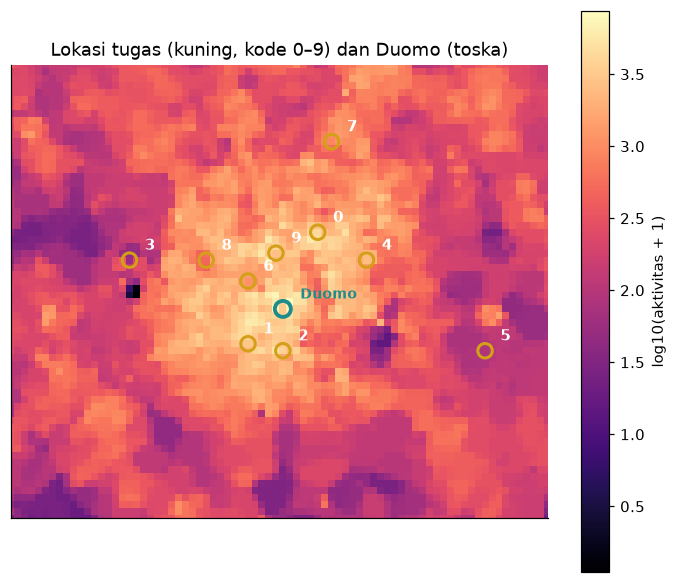

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(np.log10(grid + 1), origin="lower", cmap="magma")
ax.scatter(kolom, baris, s=110, facecolors="none", edgecolors=TEAL, linewidths=2.5)
ax.annotate("Duomo", (kolom, baris), xytext=(kolom + 2.5, baris + 1.5), color=TEAL, fontsize=9, fontweight="bold")
for kode, r in tabel.iterrows():
    b, k = divmod(r.kotak - 1, 100)
    ax.scatter(k, b, s=90, facecolors="none", edgecolors=GOLD, linewidths=2)
    ax.annotate(str(kode), (k, b), xytext=(k + 2.2, b + 1.5), color="white", fontsize=10, fontweight="bold")
ax.set_xlim(20, 97); ax.set_ylim(20, 85)
ax.set_title("Lokasi tugas (kuning, kode 0–9) dan Duomo (toska)")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(im, ax=ax, label="log10(aktivitas + 1)")
plt.tight_layout()
plt.savefig(HASIL_DIR / "peta_lokasi_tugas.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
tugas = pd.concat(potongan, ignore_index=True)
csv_tugas = DATA_DIR / "milano_tugas_10_lokasi.csv"
tugas.to_csv(csv_tugas, index=False, float_format="%.3f")
print(f"Tersimpan: {csv_tugas} ({csv_tugas.stat().st_size / 1024:.0f} KB, {len(tugas)} baris)")
f.close()

Tersimpan: data/milano_tugas_10_lokasi.csv (867 KB, 13440 baris)
